<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    SmartShip – Modeling & Evaluation
</h6>


This notebook presents the reproducible modeling results generated by `src/models/train.py`. It loads the saved order-level dataset, fitted pipeline, evaluation report, and plots.

**Before running:** execute `python -m src.features.build_dataset` and `python -m src.models.train` from the repository root. This notebook is intentionally analysis-only so Restart & Run All does not retrain the model.

In [1]:
from pathlib import Path
import json
import joblib
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'reports').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'data' / 'processed' / 'smartship_modeling_dataset.csv'
MODEL_PATH = ROOT / 'models' / 'smartship_pipeline.joblib'
REPORT_PATH = ROOT / 'reports' / 'results' / 'evaluation_summary.json'
assert DATA_PATH.exists() and MODEL_PATH.exists() and REPORT_PATH.exists(), 'Run the dataset build and training commands first.'

<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    1. Modeling dataset and target distribution
</h6>



The modeling table contains one row per delivered order with an observed outcome. Post-delivery timestamps are excluded from model predictors.

In [2]:
data = pd.read_csv(DATA_PATH)
artifact = joblib.load(MODEL_PATH)
summary = json.loads(REPORT_PATH.read_text(encoding='utf-8'))
print('Dataset shape:', data.shape)
print('Unique orders:', data.order_id.nunique())
print('Late-order distribution:')
display(data.is_late.value_counts().rename_axis('is_late').to_frame('orders'))
print('Predictor count:', len(artifact['feature_columns']))
print('Selected model:', artifact['model_name'])

Dataset shape: (96470, 24)
Unique orders: 96470
Late-order distribution:


,orders
is_late,
0,88644
1,7826


Predictor count: 21
Selected model: Extra Trees


<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    2. Final holdout metrics
</h6>



The holdout is stratified 80/20. The decision threshold was selected using out-of-fold predictions from the training partition only.

In [3]:
metric_table = pd.DataFrame([summary['test_metrics']]).T.reset_index()
metric_table.columns = ['Metric', 'Value']
metric_table['Value'] = metric_table['Value'].map(lambda x: f'{x:.4f}')
display(metric_table)
print('Selected threshold:', round(summary['oof_selected_threshold'], 4))
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(summary['test_confusion_matrix'])
print('Majority baseline:', summary['majority_baseline_test_metrics'])

,Metric,Value
0,accuracy,0.6380
1,precision_late,0.1402
2,recall_late,0.6748
3,f1_late,0.2322
4,roc_auc,0.7081
5,pr_auc,0.2150


Selected threshold: 0.3987
Confusion matrix [[TN, FP], [FN, TP]]:
[[11253, 6476], [509, 1056]]
Majority baseline: {'accuracy': 0.9188867005286617, 'precision_late': 0.0, 'recall_late': 0.0, 'f1_late': 0.0}


<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    3. Feature importance
</h6>



These values describe the fitted tree model's use of features; they are not causal explanations.

In [4]:
importance = pd.read_csv(ROOT / 'reports' / 'results' / 'feature_importance.csv')
display(importance.head(15))

,feature,importance
0,num__purchase_month,0.112571
1,num__estimated_lead_days,0.081923
2,num__customer_seller_distance_km,0.042067
3,cat__customer_state_SP,0.037936
4,cat__customer_state_RJ,0.037060
5,num__min_shipping_limit_days,0.029475
6,num__avg_shipping_limit_days,0.028901
7,num__purchase_hour,0.028588
8,num__avg_product_weight_g,0.027202
9,num__avg_product_volume_cm3,0.026199


<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    4. Evaluation figures
</h6>

confusion_matrix.png


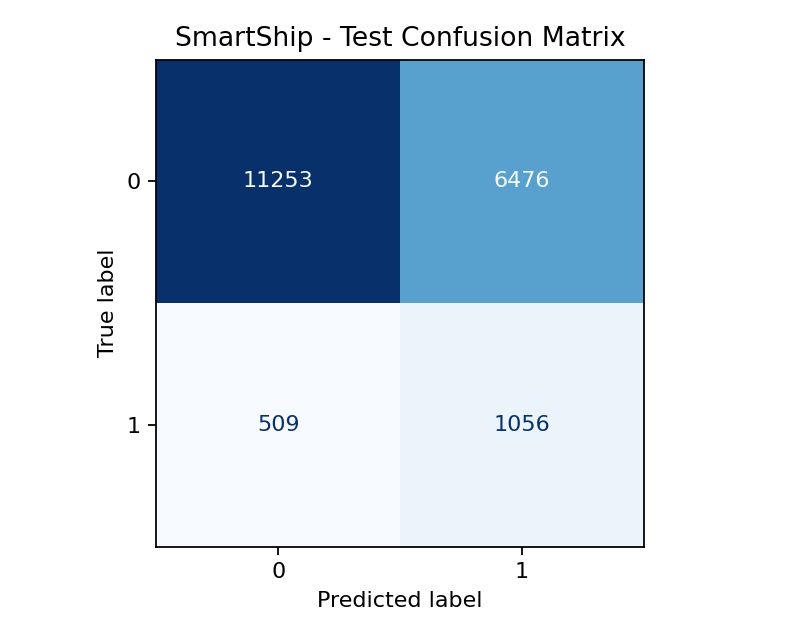

roc_curve.png


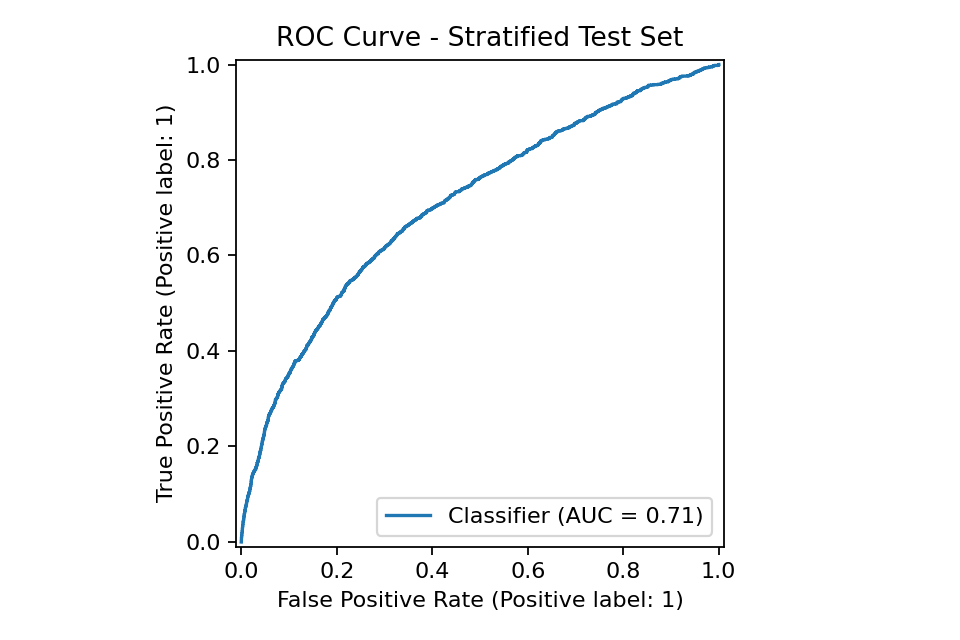

precision_recall_curve.png


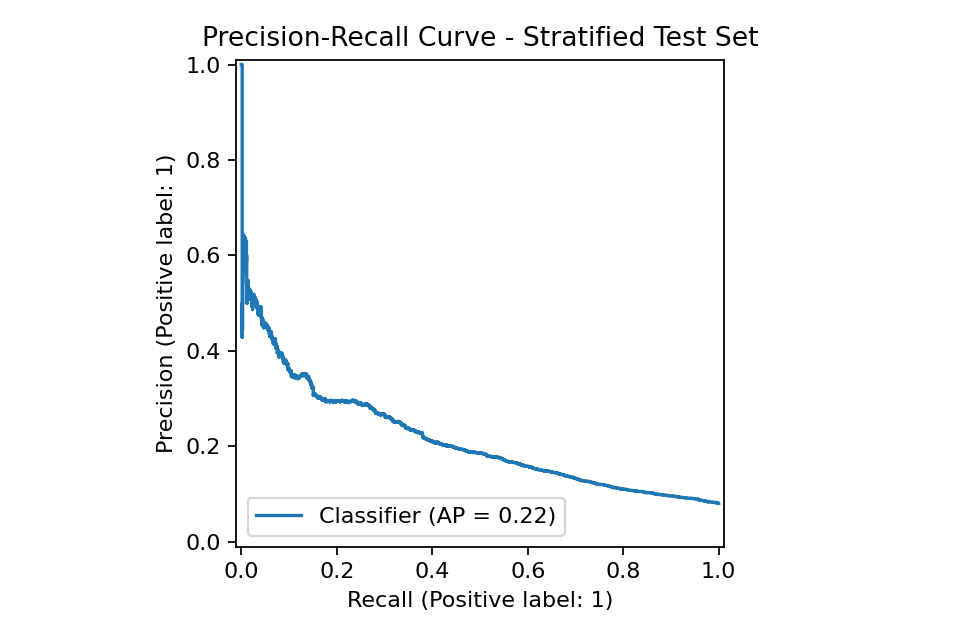

feature_importance.png


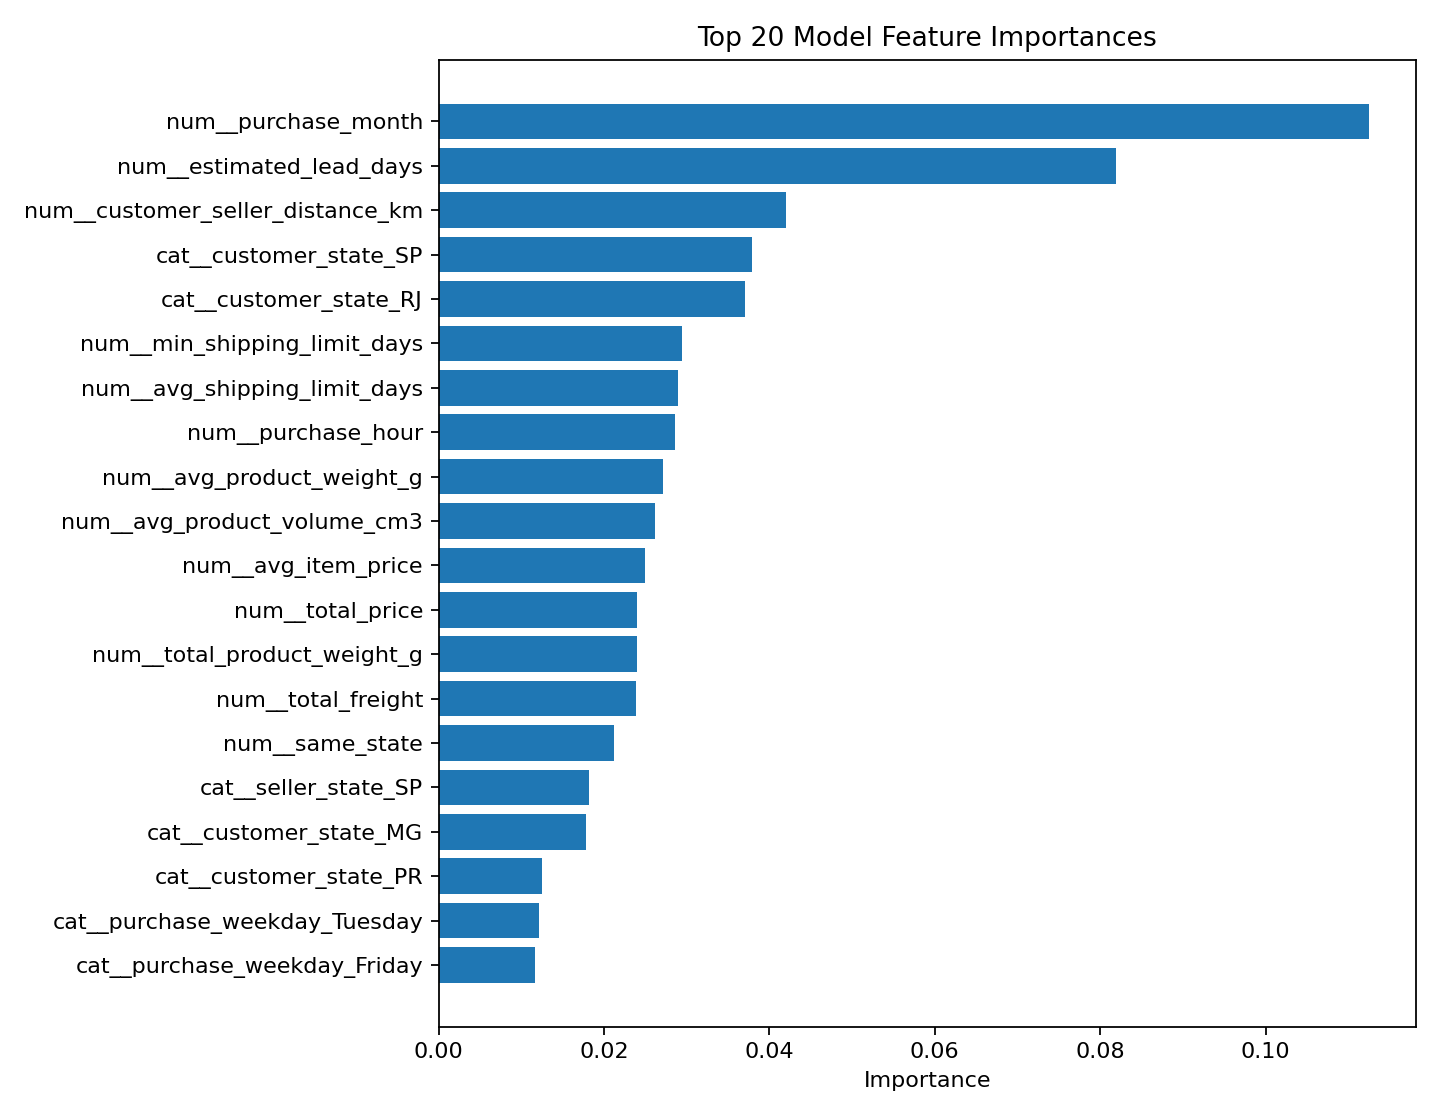

In [5]:
for filename in ['confusion_matrix.png', 'roc_curve.png', 'precision_recall_curve.png', 'feature_importance.png']:
    print(filename)
    display(Image(filename=str(ROOT / 'reports' / 'figures' / filename)))

<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    5. Interpretation and limitations
</h6>


- Late orders are a minority class, so accuracy alone is misleading.
- The selected threshold prioritizes late-order recall and produces false positives; use predictions for triage rather than automatic action.
- The stratified test results measure within-dataset discrimination. A separate chronological experiment showed weak generalization under temporal shift.
- The Olist dataset is historical (2016–2018); operational use requires recent data, calibration, monitoring and time-aware validation.